### Import des packages

In [1]:
# Importer les packages
import matplotlib.pyplot as plt
import seaborn as sns
import keras
import numpy as np
import pandas as pd
import os
import shutil
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout , BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16,DenseNet121
from keras.callbacks import EarlyStopping
import cv2

### Import des données

Le jeu de données Kaggle `tawsifurrahman/tuberculosis-tb-chest-xray-dataset` doit se trouver dans le dossier `TB_Chest_Radiography_Database` (avec les sous-dossiers `Normal` et `Tuberculosis`) à côté de ce notebook. Si le dossier n'existe pas, la cellule suivante essaie de le télécharger avec l'API Kaggle (fichier `kaggle.json` nécessaire, dans le dossier du notebook ou dans `C:\Users\<nom>\.kaggle`). Sinon, téléchargez le zip sur le site de Kaggle et décompressez-le ici.

In [2]:
# Fonction get_data (même code que utils.py du cours) : lit les images en niveaux de gris et les redimensionne en 150x150
img_size = 150
def get_data(path, label):
    data = []
    for img in os.listdir(path):
        try:
            img_arr = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshaping images to preferred size
            data.append([resized_arr, label])
        except Exception as e:
            print(e)
    return data

In [4]:
# Télécharger les données avec l'API Kaggle si le dossier n'existe pas déjà
if not os.path.exists('TB_Chest_Radiography_Database'):
  try:
    if os.path.exists('kaggle.json'):
      os.environ['KAGGLE_CONFIG_DIR'] = os.getcwd() # kaggle.json placé à côté du notebook
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    api.dataset_download_files('tawsifurrahman/tuberculosis-tb-chest-xray-dataset', path = '.', unzip = True)
  except Exception as e:
    print("Téléchargement impossible :", e)
    print("Téléchargez le zip sur Kaggle et décompressez-le pour obtenir le dossier TB_Chest_Radiography_Database")
print(os.listdir('TB_Chest_Radiography_Database'))

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset
['Normal', 'Normal.metadata.xlsx', 'README.md.txt', 'Tuberculosis', 'Tuberculosis.metadata.xlsx']


In [5]:
# Récupérer les données images converties en matrice et labelisées en utilisant la fonction get_data
Normal = get_data('TB_Chest_Radiography_Database/Normal', 0)
Tuberculosis = get_data('TB_Chest_Radiography_Database/Tuberculosis',1)

### Paramètres du mode local

Sans GPU, la recherche d'hyperparamètres sur toutes les images serait très longue. Ces paramètres réduisent le calcul (mettre `FRACTION_DONNEES = 1.0` pour utiliser toutes les images, comme sur Colab) :
- `FRACTION_DONNEES` : part des images de chaque classe conservée (la proportion Normal / Tuberculosis est gardée) ;
- `MAX_EPOCHS_TUNER` : epochs maximum du tuner (10 sur Colab avec GPU) ;
- `EPOCHS_FINAL` : epochs maximum de l'entraînement final (l'early stopping arrête avant si la loss de validation ne s'améliore plus).

In [6]:
# Paramètres du mode local
FRACTION_DONNEES = 0.5
MAX_EPOCHS_TUNER = 5
EPOCHS_FINAL = 15
# garder une fraction des images de chaque classe
Normal = Normal[:int(len(Normal) * FRACTION_DONNEES)]
Tuberculosis = Tuberculosis[:int(len(Tuberculosis) * FRACTION_DONNEES)]
len(Normal), len(Tuberculosis)

(1750, 350)

In [7]:
# Afficher l'image en matrice de la première image normal et son label
Normal[1]

[array([[233, 223, 213, ..., 225, 227, 239],
        [210, 192, 167, ..., 204, 212, 223],
        [169,  73,  25, ..., 177, 186, 198],
        ...,
        [ 17,  17,  17, ...,  12,  23,  94],
        [ 17,  17,  17, ...,  12,  23,  98],
        [ 17,  17,  17, ...,  12,  24, 102]], shape=(150, 150), dtype=uint8),
 0]

### Exploration et preparation des données

In [8]:
# Images normal et labels
normal_images = [image[0] for image in Normal]
normal_labels = [label[1] for label in Normal]
# Images tuberculosis et labels
tuberculosis_images = [image[0] for image in Tuberculosis]
tuberculosis_labels = [label[1] for label in Tuberculosis]

In [9]:
# Matrice des images
data_images = np.array(normal_images + tuberculosis_images)
# Labels des images
data_labels = np.array(normal_labels + tuberculosis_labels)

In [10]:
# Afficher la dimension
data_images.shape

(2100, 150, 150)

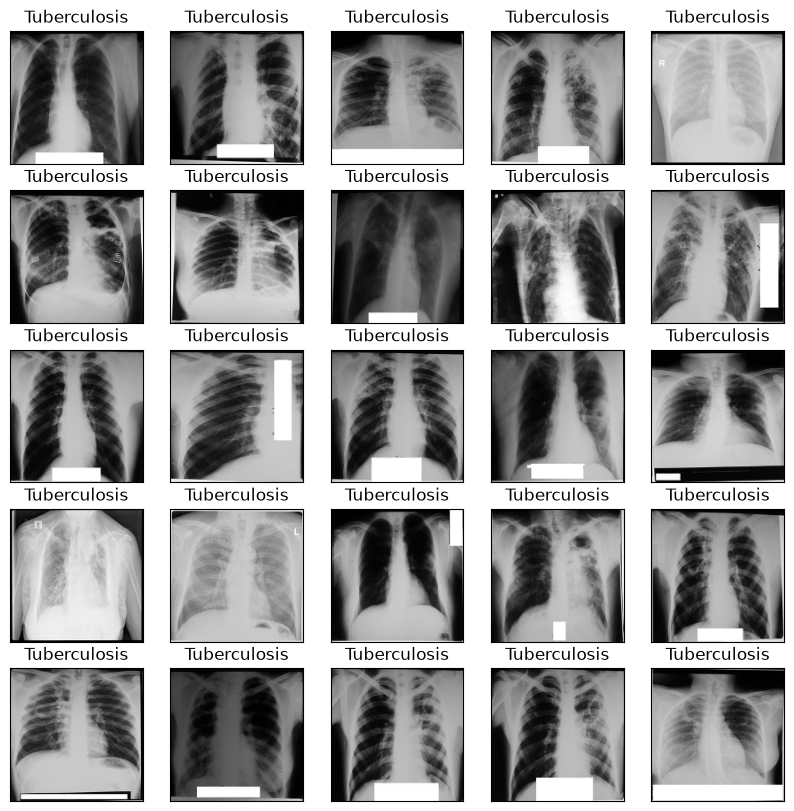

In [11]:
# Visualiser les 25 premières images des données
labels_str = ['Normal', 'Tuberculosis']
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(data_images[data_images.shape[0] - i - 1], cmap = 'gray')
  plt.title(labels_str[data_labels[data_images.shape[0] - i - 1]])

In [12]:
# Nombre d'images  dans chaque classe
pd.Series(data_labels).value_counts()

0    1750
1     350
Name: count, dtype: int64

<Axes: >

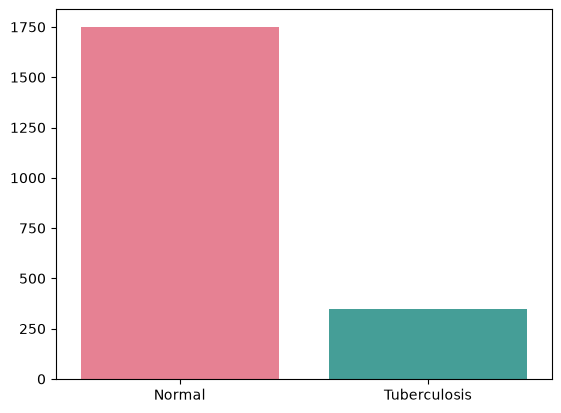

In [13]:
# Barplot du nombre d'images dans chaque classe
labels = ['Normal', 'Tuberculosis']
labels_numb = pd.Series(data_labels).value_counts().values
sns.barplot(x = labels, y =labels_numb, hue =labels,  palette= sns.husl_palette(2))

In [14]:
# spliter les données
from sklearn.model_selection import train_test_split
train_images,test_images, train_labels,test_labels = train_test_split(data_images, data_labels, test_size= 0.2, random_state=42)

In [15]:
# Normaliser (en float32 pour économiser la mémoire)
train_images,test_images = (train_images/255).astype('float32'), (test_images/255).astype('float32')

In [16]:
# Ajouter la dimension des canaux : (N, 150, 150) -> (N, 150, 150, 1)
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

In [17]:
# Répéter le canal gris 3 fois : (N, 150, 150, 1) -> (N, 150, 150, 3)
train_images = np.repeat(train_images, 3, axis=-1)
test_images = np.repeat(test_images, 3, axis=-1)

### Fonctions d'évaluation

Le jeu de données est déséquilibré (beaucoup plus d'images `Normal` que de `Tuberculosis`) : en plus de l'accuracy, on suit la **precision** et le **recall**, et on calcule le **F1-score** pour comparer les modèles.

In [18]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Fonction affichant la matrice de confusion d'un modèle sur les données validation
def CM_visualisation(model_objet):
    # Prédictions du modèle : probabilité > 0.5 => Tuberculosis (1), sinon Normal (0)
    test_pred = (model_objet.predict(test_images, verbose = 0) > 0.5).astype(int).ravel()
    # Confusion matrix
    cnf_matr = confusion_matrix(test_labels,test_pred, labels=[0,1])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Normal','Tuberculosis'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

# Fonction affichant les courbes d'accuracy et de loss (train et validation)
def courbes(history_objet):
    # Evolution de l'accuracy sur les données d'entrainement et de validation suivant les différents epochs
    plt.plot(history_objet.history['accuracy'])
    plt.plot(history_objet.history['val_accuracy'])
    plt.title("Evolution l'accuracy sur train et val data")
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'], loc = 'lower right')
    plt.show()
    # Evolution du loss sur les données d'entrainement et de validation suivant les différents epochs
    plt.plot(history_objet.history['loss'])
    plt.plot(history_objet.history['val_loss'])
    plt.title("Evolution de loss sur train et val data")
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation'], loc = 'upper right')
    plt.show()

# Fonction retournant loss, accuracy, precision, recall et F1-score d'un modèle sur des données
def metriques(model_objet, images, labels):
    res = model_objet.evaluate(images, labels, verbose = 0)
    f1 = 2 * res[2] * res[3] / (res[2] + res[3]) if (res[2] + res[3]) > 0 else 0
    return {'Loss': res[0], 'Accuracy': res[1], 'Precision': res[2], 'Recall': res[3], 'F1-score': f1}

# Dictionnaires qui vont contenir les modèles finaux et leurs résultats
models = {}
resultats_val = {}
resultats_train = {}

### Installer et importer Keras Tuner

Pour chaque modèle : recherche des hyperparamètres optimaux (Hyperband, objectif `val_accuracy`), puis réentraînement du modèle final avec ces valeurs. Le modèle est défini dans une fonction `build_model_...(hp)` ; le modèle final est construit avec cette même fonction et les hyperparamètres optimaux (`best_hps`), ce qui garantit que l'architecture finale est celle trouvée par le tuner. Comme dans le cours, le jeu `test` sert de données de validation.

In [19]:
# Installer keras tuner (et tensorboard, nécessaire à keras tuner)
%pip install keras-tuner tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# importer le package keras_tuner
import keras_tuner as kt

### Modèle de base

Hyperparamètres recherchés : filtres des 4 couches convolutives (16, 32 ou 64), neurones des 3 couches Dense (32, 64 ou 128) et learning rate d'Adam (1e-2, 1e-3 ou 1e-4).

In [21]:
# fonction build_model du modèle de base
def build_model_baseline(hp):
    # Choisir les hyperparamètres
    hp_filters1 = hp.Choice('filters1', values = [16, 32, 64])
    hp_filters2 = hp.Choice('filters2', values = [16, 32, 64])
    hp_filters3 = hp.Choice('filters3', values = [16, 32, 64])
    hp_filters4 = hp.Choice('filters4', values = [16, 32, 64])
    hp_dense1 = hp.Choice('dense1', values = [32, 64, 128])
    hp_dense2 = hp.Choice('dense2', values = [32, 64, 128])
    hp_dense3 = hp.Choice('dense3', values = [32, 64, 128])
    hp_lr = hp.Choice('learning_rate', values = [1e-2, 1e-3, 1e-4])

    model = Sequential() # initialiser l'architecture CNN
    # Couches convolutives et pooling
    model.add(Conv2D(hp_filters1, (3, 3), activation='relu', padding = 'same', input_shape=(150,150,3)))
    model.add(MaxPool2D((2, 2)))
    model.add(Conv2D(hp_filters2, (3, 3), activation='relu', padding = 'same'))
    model.add(MaxPool2D((2, 2)))
    model.add(Conv2D(hp_filters3, (3, 3), activation='relu', padding = 'same'))
    model.add(MaxPool2D((2, 2)))
    model.add(Conv2D(hp_filters4, (3, 3), activation='relu', padding = 'same'))
    model.add(MaxPool2D((2, 2)))
    # couches fully connected
    model.add(Flatten()) # couche flatten
    model.add(Dense(units = hp_dense1, activation = 'relu')) # Dense 1
    model.add(Dense(units = hp_dense2, activation = 'relu')) # Dense 2
    model.add(Dense(units = hp_dense3, activation = 'relu')) # Dense 3
    model.add(Dense(units = 1, activation = 'sigmoid')) # sortie binaire

    # compiler le modèle avec le learning rate choisi
    model.compile(optimizer = Adam(learning_rate = hp_lr), loss = 'binary_crossentropy', metrics = ['accuracy', 'precision', 'recall'])
    return model

In [22]:
# Initialiser le tuner du modèle de base
tuner_baseline = kt.Hyperband(build_model_baseline,
                     objective = 'val_accuracy',
                     max_epochs = MAX_EPOCHS_TUNER,
                     directory = 'tuner_dir',
                     project_name = 'baseline_tb',
                     overwrite = True)

# lancer la recherche avec le tuner
tuner_baseline.search(train_images, train_labels, validation_data = (test_images, test_labels), epochs = MAX_EPOCHS_TUNER, batch_size = 64)

Trial 10 Complete [00h 03m 49s]
val_accuracy: 0.8428571224212646

Best val_accuracy So Far: 0.9571428298950195
Total elapsed time: 00h 16m 46s


In [23]:
# Afficher les paramètres optimaux du modèle de base
best_hps_baseline = tuner_baseline.get_best_hyperparameters()[0]
for h_param in ['filters1', 'filters2', 'filters3', 'filters4', 'dense1', 'dense2', 'dense3', 'learning_rate']:
    print(h_param, best_hps_baseline.get(h_param))

filters1 16
filters2 64
filters3 32
filters4 16
dense1 128
dense2 128
dense3 32
learning_rate 0.001


In [24]:
# Créer le modèle de base final avec les hyperparamètres optimaux
model = build_model_baseline(best_hps_baseline)
# summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 75, 75, 64)     │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 37, 37, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 18, 18, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 18, 18, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 9, 9, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1296)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       166,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,505 (857.44 KB)

 Trainable params: 219,505 (857.44 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# Définir le early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3)
# Entrainer le modèle (compilé dans build_model_baseline : Adam, binary_crossentropy, accuracy, precision, recall)
history = model.fit(train_images, train_labels, validation_data =(test_images,test_labels), epochs = EPOCHS_FINAL, batch_size = 64, callbacks = early_stopping)
models['Baseline'] = model

Epoch 1/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 23s 626ms/step - accuracy: 0.8304 - loss: 0.4415 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.8452 - val_loss: 0.3357 - val_precision: 0.6667 - val_recall: 0.0303
Epoch 2/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 576ms/step - accuracy: 0.8804 - loss: 0.2880 - precision: 0.7610 - recall: 0.4261 - val_accuracy: 0.8500 - val_loss: 0.3019 - val_precision: 0.5161 - val_recall: 0.7273
Epoch 3/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 586ms/step - accuracy: 0.9119 - loss: 0.2238 - precision: 0.7857 - recall: 0.6585 - val_accuracy: 0.8786 - val_loss: 0.2387 - val_precision: 0.8571 - val_recall: 0.2727
Epoch 4/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 571ms/step - accuracy: 0.9244 - loss: 0.1770 - precision: 0.8552 - recall: 0.6655 - val_accuracy: 0.9571 - val_loss: 0.1441 - val_precision: 0.8529 - val_recall: 0.8788
Epoch 5/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 566ms/step - accuracy: 0.9429 - loss: 0.1475 - precision: 0.8760 - recall: 0.7711 - val_accuracy: 0.9524 -

#### Evaluation

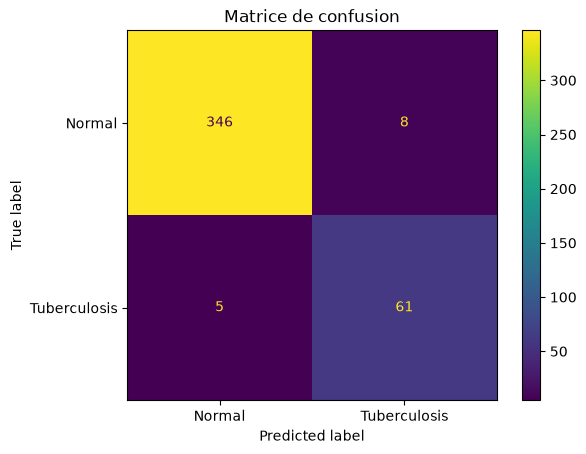

In [26]:
# matrice de confusion
CM_visualisation(model)

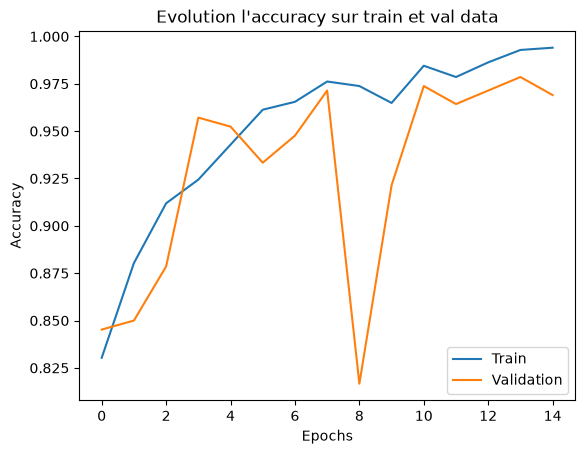

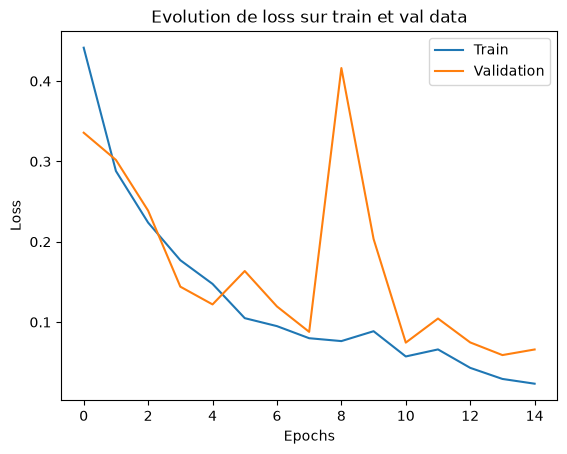

In [27]:
# Afficher les courbes d'accuracy et de loss
courbes(history)

In [28]:
# Accuracy,loss,precision et recall sur validation data et sur train data
resultats_val['Baseline'] = metriques(model, test_images, test_labels)
resultats_train['Baseline'] = metriques(model, train_images, train_labels)
print('Validation :', resultats_val['Baseline'])
print('Train :', resultats_train['Baseline'])

Validation : {'Loss': 0.06587090343236923, 'Accuracy': 0.9690476059913635, 'Precision': 0.8840579986572266, 'Recall': 0.9242424368858337, 'F1-score': 0.9037037241900407}
Train : {'Loss': 0.01787715032696724, 'Accuracy': 0.9946428537368774, 'Precision': 0.9757785201072693, 'Recall': 0.9929577708244324, 'F1-score': 0.9842931921426042}


### Modèle VGG16

Base `imagenet` gelée. Hyperparamètres recherchés : Dense 1 (256, 512 ou 1024), Dense 2 (128, 256 ou 512), Dropout 1 (0.3 à 0.6), Dropout 2 (0.2 à 0.5) et learning rate (1e-3 ou 1e-4).

In [29]:
# fonction build_model de VGG16
def build_model_vgg16(hp):
    # Choisir les hyperparamètres
    hp_dense1 = hp.Choice('dense1', values = [256, 512, 1024])
    hp_dense2 = hp.Choice('dense2', values = [128, 256, 512])
    hp_dropout1 = hp.Choice('dropout1', values = [0.3, 0.4, 0.5, 0.6])
    hp_dropout2 = hp.Choice('dropout2', values = [0.2, 0.3, 0.4, 0.5])
    hp_lr = hp.Choice('learning_rate', values = [1e-3, 1e-4])

    # Charger VGG16 préentrainé sans les couches de classification (Sans couches fully connected)
    base_vgg16 = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
    # Geler les couches de base (Leurs poids, appris sur ImageNet, restent fixes pendant l'entraînement)
    base_vgg16.trainable = False

    # Construire le modèle VGG16 avec Sequential
    vgg16_model = Sequential()
    vgg16_model.add(base_vgg16) # ajouter les couches de convolutions du modèle vgg16
    vgg16_model.add(Flatten()) # Applanir
    vgg16_model.add(Dense(units = hp_dense1, activation='relu')) # Couche Dense 1
    vgg16_model.add(Dropout(hp_dropout1)) # Couche Dropout 1
    vgg16_model.add(Dense(units = hp_dense2, activation='relu')) # Couche Dense 2
    vgg16_model.add(Dropout(hp_dropout2)) # Couche Dropout 2
    vgg16_model.add(Dense(units = 1, activation='sigmoid')) # Couche de sortie pour classification binaire

    # compiler le modèle avec le learning rate choisi
    vgg16_model.compile(optimizer = Adam(learning_rate = hp_lr), loss = 'binary_crossentropy', metrics = ['accuracy', 'precision', 'recall'])
    return vgg16_model

In [30]:
# Initialiser le tuner de VGG16
tuner_vgg16 = kt.Hyperband(build_model_vgg16,
                     objective = 'val_accuracy',
                     max_epochs = MAX_EPOCHS_TUNER,
                     directory = 'tuner_dir',
                     project_name = 'vgg16_tb',
                     overwrite = True)

# lancer la recherche avec le tuner
tuner_vgg16.search(train_images, train_labels, validation_data = (test_images, test_labels), epochs = MAX_EPOCHS_TUNER, batch_size = 64)


Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
256               |256               |dense1
256               |256               |dense2
0.4               |0.4               |dropout1
0.5               |0.5               |dropout2
0.001             |0.001             |learning_rate
2                 |2                 |tuner/epochs
0                 |0                 |tuner/initial_epoch
1                 |1                 |tuner/bracket
0                 |0                 |tuner/round

Epoch 1/2
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.8702 - loss: 0.3359 - precision: 0.6737 - recall: 0.4507

KeyboardInterrupt: 

In [31]:
# Afficher les paramètres optimaux de VGG16
best_hps_vgg16 = tuner_vgg16.get_best_hyperparameters()[0]
for h_param in ['dense1', 'dense2', 'dropout1', 'dropout2', 'learning_rate']:
    print(h_param, best_hps_vgg16.get(h_param))

dense1 256
dense2 256
dropout1 0.4
dropout2 0.5
learning_rate 0.001


In [32]:
# Créer le modèle VGG16 final avec les hyperparamètres optimaux
vgg16_model = build_model_vgg16(best_hps_vgg16)
# summary
vgg16_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,878,145 (64.39 MB)

 Trainable params: 2,163,457 (8.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [33]:
# Entraînement VGG16 (compilé dans build_model_vgg16 : Adam, binary_crossentropy, accuracy, precision, recall)
history_vgg16 = vgg16_model.fit(train_images, train_labels, validation_data= (test_images, test_labels), epochs = EPOCHS_FINAL, batch_size = 64, callbacks=early_stopping)
models['VGG16'] = vgg16_model

Epoch 1/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 276s 10s/step - accuracy: 0.8351 - loss: 0.3921 - precision: 0.5185 - recall: 0.3451 - val_accuracy: 0.9548 - val_loss: 0.1302 - val_precision: 0.9434 - val_recall: 0.7576
Epoch 2/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 289s 11s/step - accuracy: 0.9488 - loss: 0.1315 - precision: 0.8837 - recall: 0.8028 - val_accuracy: 0.9738 - val_loss: 0.0894 - val_precision: 0.9661 - val_recall: 0.8636
Epoch 3/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 262s 10s/step - accuracy: 0.9696 - loss: 0.0886 - precision: 0.9363 - recall: 0.8803 - val_accuracy: 0.9762 - val_loss: 0.0812 - val_precision: 0.9667 - val_recall: 0.8788
Epoch 4/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 257s 10s/step - accuracy: 0.9845 - loss: 0.0575 - precision: 0.9743 - recall: 0.9331 - val_accuracy: 0.9810 - val_loss: 0.0622 - val_precision: 0.9677 - val_recall: 0.9091
Epoch 5/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 288s 11s/step - accuracy: 0.9845 - loss: 0.0495 - precision: 0.9674 - recall: 0.9401 - val_accuracy: 0.9833 - val_loss: 0.

#### Evaluation

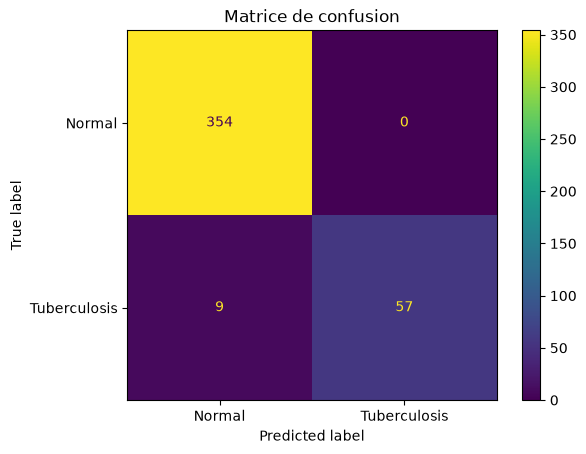

In [35]:
# matrice de confusion
CM_visualisation(vgg16_model)

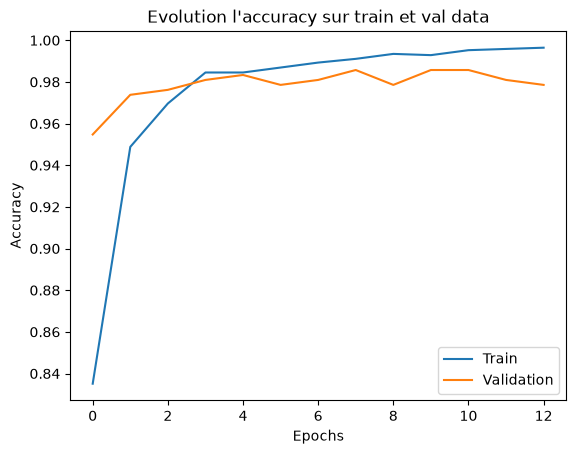

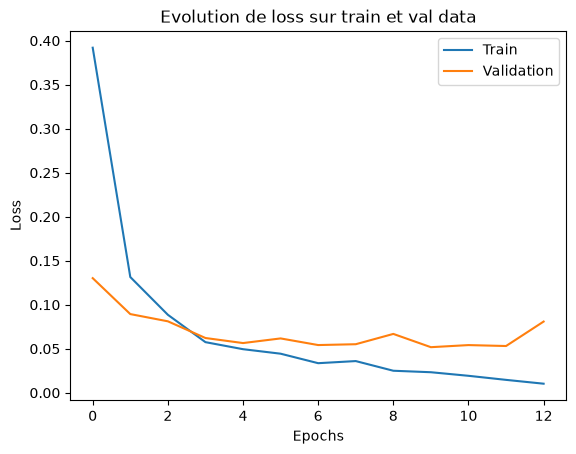

In [36]:
# Afficher les courbes d'accuracy et de loss
courbes(history_vgg16)

In [37]:
# Accuracy,loss,precision et recall sur validation data et sur train data
resultats_val['VGG16'] = metriques(vgg16_model, test_images, test_labels)
resultats_train['VGG16'] = metriques(vgg16_model, train_images, train_labels)
print('Validation :', resultats_val['VGG16'])
print('Train :', resultats_train['VGG16'])

Validation : {'Loss': 0.08092257380485535, 'Accuracy': 0.9785714149475098, 'Precision': 1.0, 'Recall': 0.8636363744735718, 'F1-score': 0.9268292745332644}
Train : {'Loss': 0.006101751700043678, 'Accuracy': 0.9970238208770752, 'Precision': 1.0, 'Recall': 0.9823943376541138, 'F1-score': 0.9911189908024455}


### Modèle DenseNet121

Mêmes hyperparamètres que VGG16, avec la base `DenseNet121` gelée.

In [38]:
# fonction build_model de DenseNet121
def build_model_densenet121(hp):
    # Choisir les hyperparamètres
    hp_dense1 = hp.Choice('dense1', values = [256, 512, 1024])
    hp_dense2 = hp.Choice('dense2', values = [128, 256, 512])
    hp_dropout1 = hp.Choice('dropout1', values = [0.3, 0.4, 0.5, 0.6])
    hp_dropout2 = hp.Choice('dropout2', values = [0.2, 0.3, 0.4, 0.5])
    hp_lr = hp.Choice('learning_rate', values = [1e-3, 1e-4])

    # Charger DenseNet121 préentrainé sans les couches de classification (Sans couches fully connected)
    base_densenet = DenseNet121(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
    # Geler les couches de base
    base_densenet.trainable = False

    # Construire le modèle DenseNet121 avec Sequential
    densenet_model = Sequential()
    densenet_model.add(base_densenet) # ajouter les couches de convolutions du modèle DenseNet121
    densenet_model.add(Flatten()) # Applanir
    densenet_model.add(Dense(units = hp_dense1, activation='relu')) # Couche Dense 1
    densenet_model.add(Dropout(hp_dropout1)) # Couche Dropout 1
    densenet_model.add(Dense(units = hp_dense2, activation='relu')) # Couche Dense 2
    densenet_model.add(Dropout(hp_dropout2)) # Couche Dropout 2
    densenet_model.add(Dense(units = 1, activation='sigmoid')) # Couche de sortie pour classification binaire

    # compiler le modèle avec le learning rate choisi
    densenet_model.compile(optimizer = Adam(learning_rate = hp_lr), loss = 'binary_crossentropy', metrics = ['accuracy', 'precision', 'recall'])
    return densenet_model

In [39]:
# Initialiser le tuner de DenseNet121
tuner_densenet = kt.Hyperband(build_model_densenet121,
                     objective = 'val_accuracy',
                     max_epochs = MAX_EPOCHS_TUNER,
                     directory = 'tuner_dir',
                     project_name = 'densenet121_tb',
                     overwrite = True)

# lancer la recherche avec le tuner
tuner_densenet.search(train_images, train_labels, validation_data = (test_images, test_labels), epochs = MAX_EPOCHS_TUNER, batch_size = 64)

Trial 10 Complete [00h 08m 37s]
val_accuracy: 0.973809540271759

Best val_accuracy So Far: 0.973809540271759
Total elapsed time: 01h 18m 24s


In [40]:
# Afficher les paramètres optimaux de DenseNet121
best_hps_densenet = tuner_densenet.get_best_hyperparameters()[0]
for h_param in ['dense1', 'dense2', 'dropout1', 'dropout2', 'learning_rate']:
    print(h_param, best_hps_densenet.get(h_param))

dense1 512
dense2 256
dropout1 0.3
dropout2 0.5
learning_rate 0.0001


In [41]:
# Créer le modèle DenseNet121 final avec les hyperparamètres optimaux
densenet_model = build_model_densenet121(best_hps_densenet)
# summary
densenet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     8,389,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,558,209 (59.35 MB)

 Trainable params: 8,520,705 (32.50 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [42]:
# Entraînement DenseNet121 (compilé dans build_model_densenet121 : Adam, binary_crossentropy, accuracy, precision, recall)
history_densenet = densenet_model.fit(train_images, train_labels, validation_data = (test_images,test_labels), epochs = EPOCHS_FINAL, batch_size = 64, callbacks=early_stopping)
models['DenseNet121'] = densenet_model

Epoch 1/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 264s 9s/step - accuracy: 0.8238 - loss: 0.5111 - precision: 0.4748 - recall: 0.3979 - val_accuracy: 0.9190 - val_loss: 0.1766 - val_precision: 0.9211 - val_recall: 0.5303
Epoch 2/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 188s 6s/step - accuracy: 0.9494 - loss: 0.1364 - precision: 0.8783 - recall: 0.8134 - val_accuracy: 0.9548 - val_loss: 0.1171 - val_precision: 0.8983 - val_recall: 0.8030
Epoch 3/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 213s 7s/step - accuracy: 0.9649 - loss: 0.1030 - precision: 0.9182 - recall: 0.8697 - val_accuracy: 0.9643 - val_loss: 0.0973 - val_precision: 0.9048 - val_recall: 0.8636
Epoch 4/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 192s 6s/step - accuracy: 0.9667 - loss: 0.0885 - precision: 0.9254 - recall: 0.8732 - val_accuracy: 0.9690 - val_loss: 0.0904 - val_precision: 0.9492 - val_recall: 0.8485
Epoch 5/15
27/27 ━━━━━━━━━━━━━━━━━━━━ 186s 7s/step - accuracy: 0.9726 - loss: 0.0773 - precision: 0.9132 - recall: 0.9261 - val_accuracy: 0.9714 - val_loss: 0.0882 

#### Evaluation

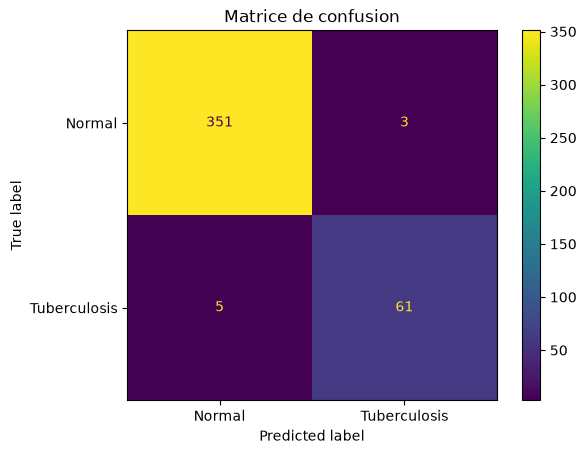

In [43]:
# Matrice de confusion
CM_visualisation(densenet_model)

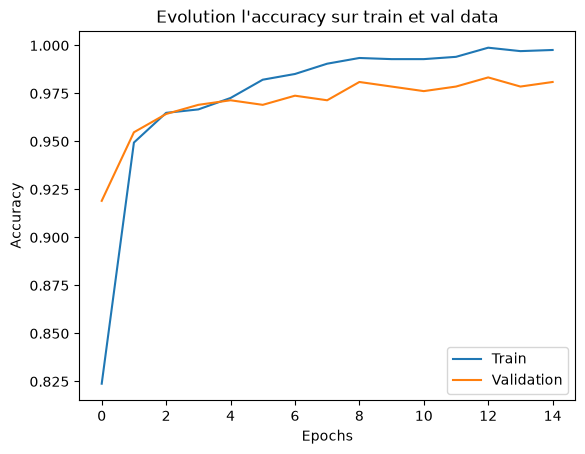

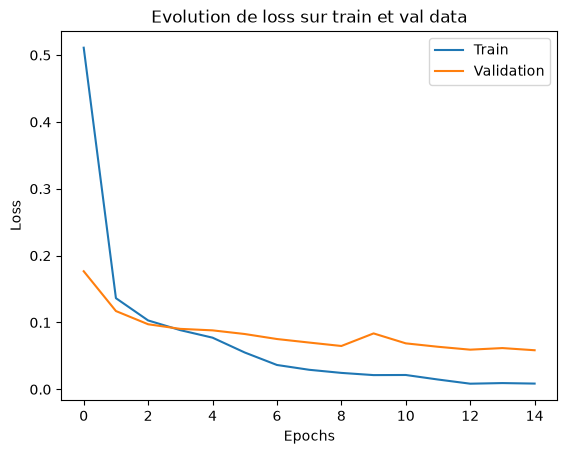

In [44]:
# Afficher les courbes d'accuracy et de loss
courbes(history_densenet)

In [45]:
# Accuracy,loss,precision et recall sur validation data et sur train data
resultats_val['DenseNet121'] = metriques(densenet_model, test_images, test_labels)
resultats_train['DenseNet121'] = metriques(densenet_model, train_images, train_labels)
print('Validation :', resultats_val['DenseNet121'])
print('Train :', resultats_train['DenseNet121'])

Validation : {'Loss': 0.0584583505988121, 'Accuracy': 0.9809523820877075, 'Precision': 0.953125, 'Recall': 0.9242424368858337, 'F1-score': 0.9384615449792534}
Train : {'Loss': 0.002125827129930258, 'Accuracy': 0.9988095164299011, 'Precision': 0.9964788556098938, 'Recall': 0.9964788556098938, 'F1-score': 0.9964788556098938}


### Comparaison des trois modèles

In [46]:
# Tableau comparatif des métriques sur les données de validation
comparaison_val = pd.DataFrame(resultats_val).T
comparaison_val

,Loss,Accuracy,Precision,Recall,F1-score
Baseline,0.065871,0.969048,0.884058,0.924242,0.903704
VGG16,0.080923,0.978571,1.000000,0.863636,0.926829
DenseNet121,0.058458,0.980952,0.953125,0.924242,0.938462


In [47]:
# Tableau comparatif des métriques sur les données d'entrainement
comparaison_train = pd.DataFrame(resultats_train).T
comparaison_train

,Loss,Accuracy,Precision,Recall,F1-score
Baseline,0.017877,0.994643,0.975779,0.992958,0.984293
VGG16,0.006102,0.997024,1.000000,0.982394,0.991119
DenseNet121,0.002126,0.998810,0.996479,0.996479,0.996479


### Télécharger le modèle le plus performant

Le jeu de données étant déséquilibré, le meilleur modèle est choisi avec le **F1-score** sur les données de validation (compromis entre precision et recall), et non avec l'accuracy seule. On vérifie ainsi si c'est toujours VGG16 après la recherche d'hyperparamètres.

In [48]:
# Choisir et sauvegarder le meilleur modèle
best_name = comparaison_val['F1-score'].idxmax()
best_model = models[best_name]
print('Meilleur modèle :', best_name)
best_model.save('tuberculosis_best_model.h5')
best_model.save('tuberculosis_best_model.keras')

Meilleur modèle : DenseNet121


In [49]:
# Copier le meilleur modèle dans le dossier du projet (utilisé par l'application Streamlit)
dossier = 'Projet/TP5'
os.makedirs(dossier, exist_ok = True)
shutil.copy('tuberculosis_best_model.h5', dossier)
shutil.copy('tuberculosis_best_model.keras', dossier)
os.listdir(dossier)

['tuberculosis_best_model.h5', 'tuberculosis_best_model.keras']

### Prédictions

La fonction de prétraitement reproduit **exactement** celui de l'entraînement (`get_data` : image lue en niveaux de gris, redimensionnée en 150×150, divisée par 255, canal répété 3 fois). Elle sera reprise telle quelle dans `app.py`.

In [50]:
# Fonction convertissant l'image à la dimension exacte utilisée sur le training
import cv2
from PIL import Image

def imageToArray(image):
  width, height = 150, 150  # dimensions requises par notre modèle

  image = np.array(image.convert('L'))        # niveaux de gris (comme cv2.IMREAD_GRAYSCALE dans get_data)
  image = cv2.resize(image, (width, height))  # même redimensionnement que get_data
  image_array = image / 255.0                 # Normaliser les valeurs des pixels entre 0 et 1
  image_array = np.repeat(image_array[..., np.newaxis], 3, axis=-1)  # répéter le canal gris 3 fois

  # Redimensionner la matrice image pour qu'elle correspond à la forme d'entrée de notre modèle
  return image_array.reshape(-1, width, height, 3).astype('float32')

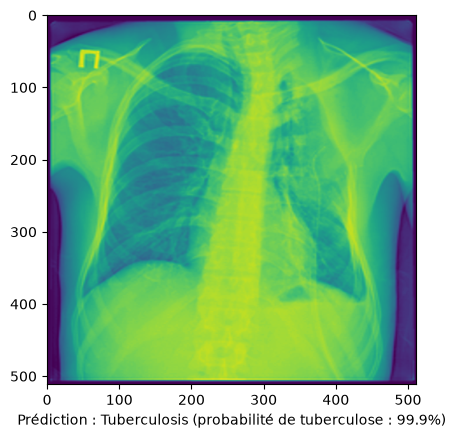

In [51]:
# Predictions avec le meilleur modèle
class_names = ['Normal', 'Tuberculosis']
image_path = 'images_test/Tuberculosis_test1.png'
if os.path.exists(image_path):
  image = Image.open(image_path)
else:
  # si l'image n'existe pas, on utilise la première image du jeu de validation
  image = Image.fromarray((test_images[0][..., 0] * 255).astype('uint8'))
  print("Image 'images_test/Tuberculosis_test1.png' introuvable : utilisation d'une image du jeu de validation")
proba = float(best_model.predict(imageToArray(image), verbose = 0)[0][0])
pred = class_names[int(np.round(proba))]
plt.imshow(image) # afficher l'image
plt.xlabel(f'Prédiction : {pred} (probabilité de tuberculose : {proba:.1%})')
plt.show()

### Préparation pour le déploiement avec Streamlit

In [52]:
# Fonction de prédiction retournant la probabilité de chaque classe (même prétraitement que l'application Streamlit)
from tensorflow.keras.models import load_model
model_app = load_model('tuberculosis_best_model.h5')

def predict(image):
    p_tb = float(model_app.predict(imageToArray(image), verbose = 0)[0][0])
    return {class_names[1]: p_tb, class_names[0]: 1.0 - p_tb}

# Tester la fonction sur une image
predict(image)

{'Tuberculosis': 0.9989782571792603, 'Normal': 0.001021742820739746}